In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
from lppls import lppls
from tqdm import tqdm

[*********************100%***********************]  1 of 1 completed


735060.7127745915 0.15735317876303823 11.909873473485575 -12.844930879784021 6.5257462934412676 0.15379160528666702 0.14328066664046044 0.055879409657898414 -3.889847975869928 0.5606165677877073


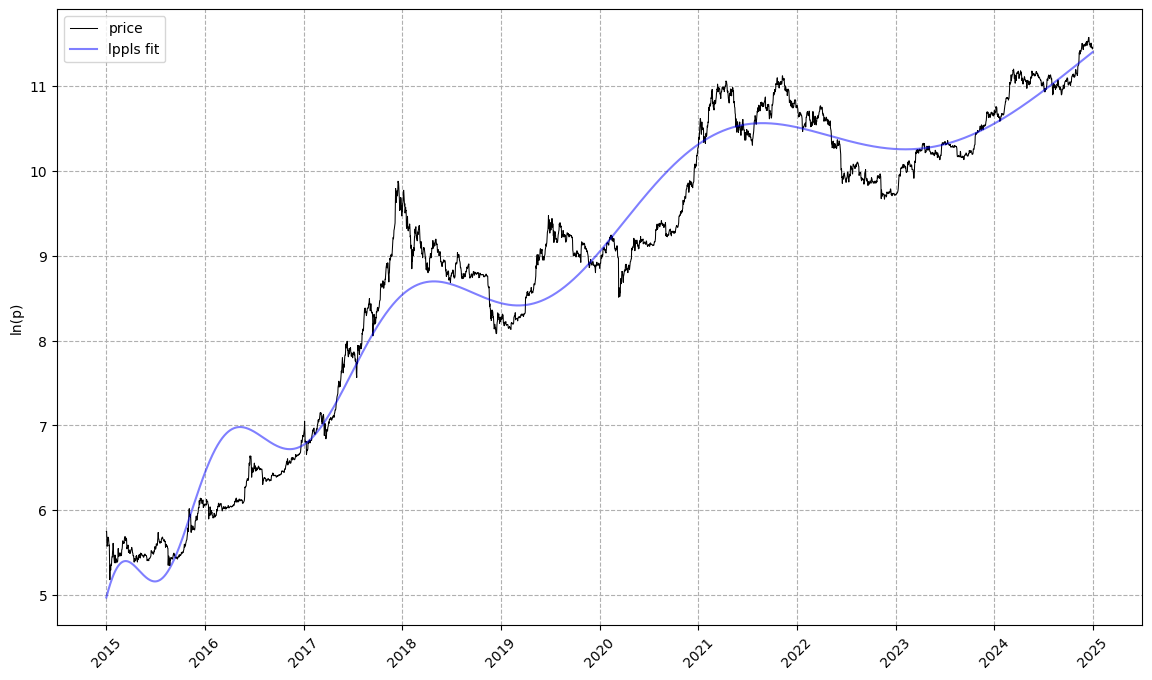

In [2]:
# 1) Dane
data = yf.download("BTC-USD", start="2015-01-01", end="2025-01-01")
# data = yf.download("^GSPC", start="2000-01-01", end="2025-08-31")

data = data.reset_index()

price_col = "Adj Close" if "Adj Close" in data.columns else "Close"
df = data[["Date", price_col]].dropna().sort_values("Date").reset_index(drop=True)
df = df.rename(columns={price_col: "price"})

# 2) Wektory czasu i ceny (1D)
time = df["Date"].map(pd.Timestamp.toordinal).to_numpy(dtype=float)
price = np.log(df["price"].to_numpy(dtype=float))

# 3) Jednolita filtracja niefinitych wierszy (unikamy problemów z maską)
stack = np.column_stack([time, price])             # shape (N, 2)
stack = stack[np.isfinite(stack).all(axis=1)]      # tylko wiersze w pełni „finite”
time, price = stack[:, 0], stack[:, 1]             # z powrotem na 2 wektory 1D

# 4) Observations: (2, N)
observations = np.vstack([time, price])

# 5) LPPLS
MAX_SEARCHES = 50
model = lppls.LPPLS(observations=observations)
tc, m, w, a, b, c, c1, c2, O, D = model.fit(MAX_SEARCHES)
model.plot_fit(show_tc=True)
print(tc, m, w, a, b, c, c1, c2, O, D)

In [3]:
# compute the confidence indicator
res = model.mp_compute_nested_fits(
    workers=10,
    window_size=240, 
    smallest_window_size=30, 
    outer_increment=1, 
    inner_increment=5, 
    max_searches=50,
    # filter_conditions_config={} # not implemented in 0.6.x
)

model.plot_confidence_indicators(res)

  0%|          | 0/3414 [02:24<?, ?it/s]


KeyboardInterrupt: 